# WSM 2025 — Stress Regime and SHmax Orientation Analysis

**Study area:** Germany and surrounding regions, defined by a longitude–latitude bounding box of **5°–16° E, 47°–55° N** (rather than national borders).  
**Source:** World Stress Map (WSM) 2025 database.  
**Scope:** Quality A–C observations with valid coordinates and available SHmax azimuths.

## Objectives

1. Describe the frequency and geographic distribution of stress-regime classifications.
2. Calculate the axial mean SHmax orientation and mean resultant length, accounting for the 180° periodicity of stress axes.
3. Compare the northern and southern halves of the study area using an exploratory 51° N division.
4. Assess sensitivity of these summaries to observations sharing exact coordinate pairs.

All results describe the selected WSM observations, not estimated area-wide stress magnitudes or a spatially uniform sample.

## 1. Setup and data availability

**Input files (relative project paths):**

- `WSM_Database_2025.csv` — obtain the WSM 2025 data from the official project.
- `natural_earth/ne_110m_admin_0_countries.shp` — Natural Earth Admin 0 countries; retain the related `.shx`, `.dbf`, and `.prj` files in the same directory.

Requirements: Python 3, `pandas`, `numpy`, `geopandas`, `matplotlib` and their geospatial dependencies.  Notebook figures are drawn from the observations; marker colors and symbol sizes are cartographic encodings, not stress magnitudes.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

DATA_PATH = Path("WSM_Database_2025.csv")
COUNTRIES_PATH = Path("natural_earth/ne_110m_admin_0_countries.shp")

if not DATA_PATH.is_file():
    raise FileNotFoundError(f"WSM input data not found: {DATA_PATH}")
if not COUNTRIES_PATH.is_file():
    raise FileNotFoundError(f"Natural Earth basemap not found: {COUNTRIES_PATH}")

## 2. Build the quality-filtered regional dataset

First filter for valid latitude/longitude, **available** azimuths (thus excluding the `999` unavailable-orientation code), and WSM quality classes A–C. Then create a WGS 84 point GeoDataFrame and subset by the geographic bounding box.

The `AZI` column gives an orientation relative to **geographic north**; reprojecting point geometry does not alter this attribute.

In [2]:
df = pd.read_csv(DATA_PATH, low_memory=False)

valid = (
    df["LAT"].between(-90, 90)
    & df["LON"].between(-180, 180)
    & df["AZI"].between(0, 180)
    & df["QUALITY"].isin(["A", "B", "C"])
)
df_mapping_abc = df.loc[valid].copy()

gdf = gpd.GeoDataFrame(
    df_mapping_abc,
    geometry=gpd.points_from_xy(df_mapping_abc["LON"], df_mapping_abc["LAT"]),
    crs="EPSG:4326",
)
gdf_region = gdf.loc[
    gdf["LON"].between(5, 16) & gdf["LAT"].between(47, 55)
].copy()

print("Quality-filtered global observations:", len(gdf))
print("Regional observations:", len(gdf_region))
print("Regional geometry CRS:", gdf_region.crs)
assert len(gdf_region) == 584, "Check dataset version and selection criteria"

Quality-filtered global observations: 77364
Regional observations: 584
Regional geometry CRS: EPSG:4326


## 3. Stress-regime composition

`U` is an *undetermined* regime, not a physical faulting regime. Report composition both across all selected observations and after excluding `U`; the latter changes the **denominator**, not the counts of classified records.

In [3]:
regime_counts = gdf_region["REGIME"].value_counts()
regime_percent_all = (regime_counts / len(gdf_region) * 100).round(2)
gdf_known = gdf_region.loc[gdf_region["REGIME"] != "U"].copy()
regime_percent_known = (
    gdf_known["REGIME"].value_counts(normalize=True) * 100
).round(2)

regime_summary = pd.DataFrame({
    "observations": regime_counts,
    "percent_all": regime_percent_all,
    "percent_classified": regime_percent_known,
})
print(f"Classified regime observations: {len(gdf_known)}")
display(regime_summary.round(2))

Classified regime observations: 299


,observations,percent_all,percent_classified
REGIME,,,
NF,64,10.96,21.40
NS,17,2.91,5.69
SS,173,29.62,57.86
TF,33,5.65,11.04
TS,12,2.05,4.01
U,285,48.80,NaN


In this dataset, **285/584 (48.80%)** records had an undetermined regime. Of the **299** records with determined regimes, **173 (57.86%)** were strike-slip (`SS`), the largest classified category. Uneven observation density means these percentages describe the *sample*, not the geographic proportion of each regime.

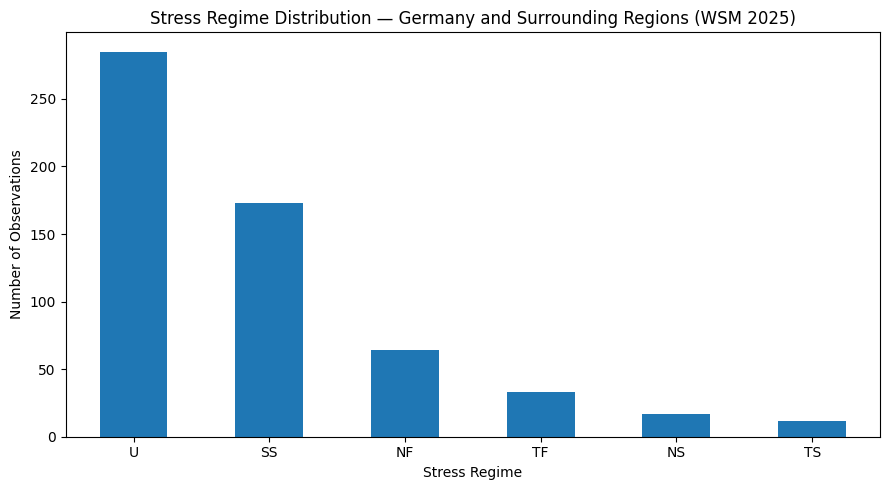

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
regime_counts.plot(kind="bar", ax=ax)
ax.set_title("Stress Regime Distribution — Germany and Surrounding Regions (WSM 2025)")
ax.set_xlabel("Stress Regime")
ax.set_ylabel("Number of Observations")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()

## 4. Spatial distribution of stress regimes

Reproject the country boundaries and observation point geometries into **EPSG:3035** for a common map coordinate system. Plot the categories, with explicit map bounds and equal aspect ratio. `U` observations remain visible to show where a regime is not determined.

In [5]:
world = gpd.read_file(COUNTRIES_PATH)
world_projected = world.to_crs("EPSG:3035")
gdf_region_projected = gdf_region.to_crs("EPSG:3035")

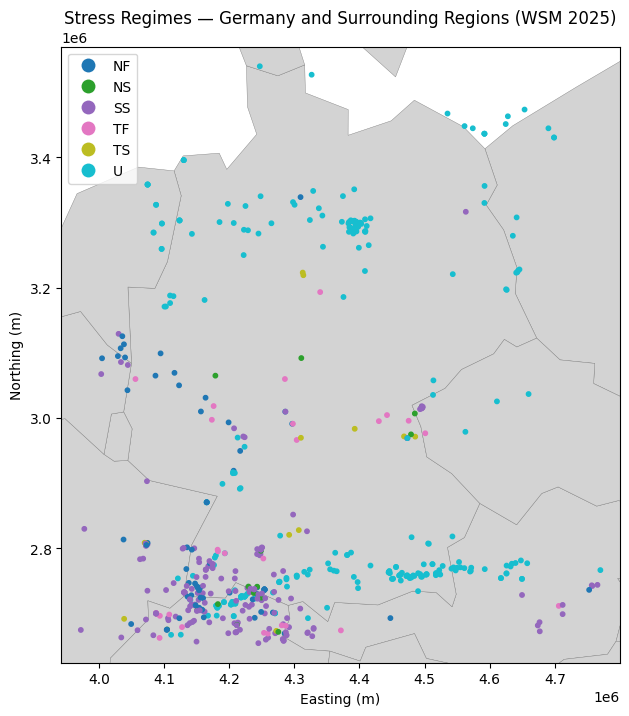

In [6]:
fig, ax = plt.subplots(figsize=(10, 8))
world_projected.plot(ax=ax, color="lightgray", edgecolor="gray", linewidth=0.3)
gdf_region_projected.plot(
    ax=ax, column="REGIME", categorical=True, legend=True, markersize=10
)

min_x, min_y, max_x, max_y = gdf_region_projected.total_bounds
margin = 30000
ax.set_xlim(min_x - margin, max_x + margin)
ax.set_ylim(min_y - margin, max_y + margin)
ax.set_title("Stress Regimes — Germany and Surrounding Regions (WSM 2025)")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")
plt.show()

The map indicates a strong concentration of measurements in the southern part of the selected area and substantial geographic variability in regime labels. Overplotted points can hide multiple records at the same location. The map does not represent stress intensity.

## 5. SHmax axial orientation statistics

An SHmax orientation describes a **line**, not an arrow: angles separated by **180°** represent the same axis. Ordinary arithmetic means can therefore be misleading near the 0°/180° boundary.

Use an **axial circular mean**: double each azimuth, average its sine and cosine, recover the angle using `arctan2`, halve it, and express the result in `[0, 180)`. The mean resultant length (R̄, from 0 to 1) measures net concentration, **not the fraction or percentage of aligned observations**.

A single function calculates the overall, subregional, and sensitivity summaries. If the mean sine and cosine both approach zero, the mean direction becomes unstable or undefined.

In [7]:
def axial_stats(azimuth_degrees):
    """Return axial mean in degrees [0, 180), R-bar, and sample size."""
    angles = np.asarray(azimuth_degrees, dtype=float)
    angles = angles[np.isfinite(angles)]
    if angles.size == 0:
        raise ValueError("No valid azimuths")
    doubled = np.deg2rad(2 * angles)
    mean_cos = np.mean(np.cos(doubled))
    mean_sin = np.mean(np.sin(doubled))
    r_bar = float(np.hypot(mean_cos, mean_sin))
    axial_mean = (
        np.rad2deg(np.arctan2(mean_sin, mean_cos)) / 2
    ) % 180 if r_bar > 1e-12 else float("nan")
    return {"n": int(angles.size), "axial_mean_deg": float(axial_mean), "R_bar": r_bar}

overall = axial_stats(gdf_region["AZI"])
print("Overall axial statistics:", overall)
print("Arithmetic mean for comparison:", round(gdf_region["AZI"].mean(), 2))

Overall axial statistics: {'n': 584, 'axial_mean_deg': 163.1174658145339, 'R_bar': 0.6278144970542879}
Arithmetic mean for comparison: 118.07


**Overall sample:** 584 observations; axial mean **163.12°** (NNW–SSE); **R̄ = 0.628**. The ordinary arithmetic mean was **118.07°**, demonstrating why the axial formulation matters. The resultant length indicates a substantial net concentration but not perfect alignment or a percentage of observations within any angular tolerance.

### Azimuth frequency distribution

A 10°-bin histogram describes the sample distribution. Because 0° and 180° are **equivalent endpoints** of the axial scale, apparent concentrations at both ends may belong to one orientation sector rather than two independent modes.

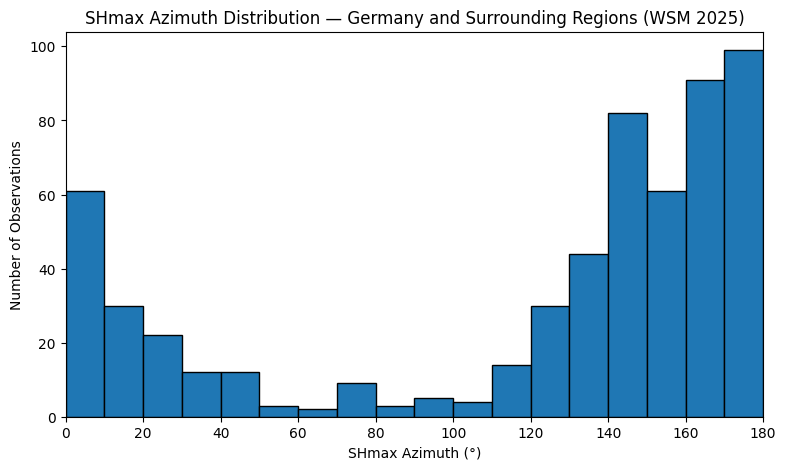

In [8]:
azimuths = gdf_region["AZI"].to_numpy()

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(azimuths, bins=18, range=(0, 180), edgecolor="black")
ax.set_title("SHmax Azimuth Distribution — Germany and Surrounding Regions (WSM 2025)")
ax.set_xlabel("SHmax Azimuth (°)")
ax.set_ylabel("Number of Observations")
ax.set_xlim(0, 180)
plt.show()

The azimuth histogram shows that observations are concentrated in the 130°–180° sector with additional counts near 0°–30°; relatively few lie around 50°–110°. These observations are consistent with a broad preferred NNW–SSE to N–S axial alignment. Histogram peaks alone do not establish distinct geological regimes.

## 6. Exploratory geographic comparison

Divide the bounding box at **51° N**, solely as an exploratory north–south split; this is not a mapped tectonic boundary. Compute the axial mean and R̄ for each subset using the same function to avoid mixing intermediate variables from different analyses.

In [9]:
gdf_south = gdf_region.loc[gdf_region["LAT"] < 51].copy()
gdf_north = gdf_region.loc[gdf_region["LAT"] >= 51].copy()
assert len(gdf_north) + len(gdf_south) == len(gdf_region)

north = axial_stats(gdf_north["AZI"])
south = axial_stats(gdf_south["AZI"])
regional_summary = pd.DataFrame({
    "All observations": overall,
    "North (>= 51°N)": north,
    "South (< 51°N)": south,
}).T
print(regional_summary.round(3).to_string())

                      n  axial_mean_deg  R_bar
All observations  584.0         163.117  0.628
North (>= 51°N)   122.0           0.273  0.445
South (< 51°N)    462.0         160.399  0.700


**Regional comparison:**

| Group | Number of observations | Axial mean | R̄ |
|---|---:|---:|---:|
| Entire study area | 584 | 163.12° | 0.628 |
| North (≥51°N) | 122 | 0.27° | 0.445 |
| South (<51°N) | 462 | 160.40° | 0.700 |

The northern axial mean is near **N–S** with weaker net alignment, whereas the southern sample is more concentrated along a **NNW–SSE** axis. Taking account of 180° periodicity, the two sample means differ by about **19.87°**. This is a descriptive difference; no formal uncertainty interval or significance test is claimed. The much larger southern sample contributes more strongly to the overall result.

## 7. Sensitivity to repeated coordinate pairs

Multiple WSM records may share exact latitude and longitude but represent distinct measurements. To assess their influence on these descriptive summaries, keep the **first** record at each exact coordinate pair and recompute the statistics. This is an intentionally simple sensitivity test, **not** a recommendation to remove valid co-located measurements from the scientific database.

In [10]:
location_counts = gdf_region[["LAT", "LON"]].drop_duplicates().shape[0]
extra_repeated_records = gdf_region.duplicated(subset=["LAT", "LON"]).sum()
records_in_repeated_groups = gdf_region.duplicated(
    subset=["LAT", "LON"], keep=False
).sum()

gdf_unique = gdf_region.drop_duplicates(subset=["LAT", "LON"]).copy()
unique = axial_stats(gdf_unique["AZI"])

comparison = pd.DataFrame({
    "Original sample": overall,
    "One record per location": unique,
}).T
print("Unique coordinate pairs:", location_counts)
print("Additional repeated-coordinate records:", extra_repeated_records)
print("Records belonging to repeated-location groups:", records_in_repeated_groups)
print(comparison.round(3).to_string())

# Axial difference is the shorter angular separation (0–90 degrees).
delta = abs(overall["axial_mean_deg"] - unique["axial_mean_deg"])
axial_difference = min(delta, 180 - delta)
print(f"Difference between sample means: {axial_difference:.3f}°")

Unique coordinate pairs: 524
Additional repeated-coordinate records: 60
Records belonging to repeated-location groups: 99
                             n  axial_mean_deg  R_bar
Original sample          584.0         163.117  0.628
One record per location  524.0         162.813  0.623
Difference between sample means: 0.304°


**Sensitivity results:** 524 unique coordinate pairs; 60 records beyond the first occurrence; 99 records belonging to repeated-location groups. Retaining one record per coordinate pair gave **162.81°**, **R̄ = 0.623**, compared with the original **163.12°**, **R̄ = 0.628**. The sample mean shifts by only about **0.30°**, suggesting low sensitivity to this particular first-record selection rule. This check does not correct uneven spatial coverage or evaluate which co-located measurements are independent.

## 8. Conclusions, limitations, and reproducibility

### Main findings

- **Regimes:** Nearly half of selected records have undetermined stress regime (`U`). Among classified records, strike-slip (`SS`) is the most frequent class.
- **Orientation:** The selected observations have an axial mean SHmax orientation of about **163.12°**, with mean resultant length **0.628**. The histogram is consistent with a broad preferred sector near NNW–SSE / N–S.
- **North–south comparison:** The northern subset has a near-N–S sample mean and lower concentration (**R̄ ≈ 0.445**) than the southern subset (**R̄ ≈ 0.700**). The difference between sample means is approximately **19.87°**.
- **Repeat-location sensitivity:** A first-record-per-location test changes the overall axial mean by about **0.30°** and R̄ by roughly **0.0044**.

### Interpretation boundaries

The selection includes WSM quality A–C records with available SHmax azimuths only, within a rectangular Germany-centered region. Observation density is uneven; repeated coordinates and differing acquisition methods/depths may affect interpretation. The exploratory 51° N split is not a geological boundary, and the descriptive difference has not been statistically tested. R̄ measures concentration, **not the percentage** within any preferred direction. Neither these maps nor the axial mean estimate stress magnitude.

### Data and attribution

Analyses use the World Stress Map Database Release 2025 and Natural Earth 1:110m country boundaries, referenced through relative project paths. Dataset provenance, attribution, licensing, and environment requirements are documented in the repository README.
